<table align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/gimseng/99-ML-Learning-Projects/blob/master/001/exercise/starter-notebook.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
</table>

## A starter notebook with tasks listed to help you get started on your first machine learning project

### First phase: Inspecting the data
(this process is where you familiarize yourself with the data)

Tasks:
- Inspect the data
- Check for null/missing values
- View statistical details using ``describe()``

Step one has been done for you
After finishing the tasks think of the following:

What can you infer from the statistical measures? like possible outliers?

**Important note:**

The data is already split into train.csv and test.csv, you generally would build your model using the train.csv **without** using any test.csv data as that would lead to overfitting your model

#### Reminder: you do not have to stick to the tasks listed word for word, the tasks are listed as a guide to guide you.
#### Feel free to explore more and do more on your own!

In [1]:
# imports
import pandas as pd

In [2]:
project_url = 'https://raw.githubusercontent.com/gimseng/99-ML-Learning-Projects/'
data_path = 'master/001/data/'
train = pd.read_csv(project_url+data_path+'train.csv')
test = pd.read_csv(project_url+data_path+'test.csv')

train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [5]:
print("Shape:", train.shape)
print("\nMissing values:")
print(train.isnull().sum())


Shape: (891, 12)

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [7]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
print("Survival counts:")
print(train['Survived'].value_counts())

print("\nSurvival percentage:")
print(train['Survived'].value_counts(normalize=True) * 100)

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentage:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


In [ ]:
"""
1. Survival Rate is Low

Mean of Survived = 0.38
the dataset is imbalanced — more 0s than 1s. Our model needs to learn from an uneven playing field.

2. Fare is Heavily Skewed

Mean fare = £32 but 50% of passengers paid £14.45 or less
Someone paid £512 — that's 35x the median
This means a small group of very wealthy passengers skew the average significantly

3. Most People Traveled Alone

50% of passengers had 0 siblings/spouses and 0 parents/children
Yet someone had 8 siblings/spouses aboard — likely a large immigrant family

4. Age Has Significant Spread

Range is 0.42 to 80 years — very wide
Standard deviation = 14.5
ages are spread out, not clustered tightly around the mean
The 177 missing ages could bias our model if not handled carefully

5. Class is Skewed Toward 3rd Class

Mean Pclass = 2.3, median = 3
majority were 3rd class passengers who paid low fares and had the worst survival odds

"""


### Second phase: Data Analysis and Visualization (this process is where you explore the data, clean it and infer some insights from it)
Tasks:
- Plot the gender distribution of passengers on board
- Plot the rate of men and women who survived and who didnt survive
- Plot the survival rate by "Pclass" (male and female counted together in each Pclass)
- Plot the survival rate by males only in each "Pclass"
- Plot the survival rate by females only in each "Pclass"

Think about the plots that you just did, what can you infer from them?
Now lets have a look at the columns, there are always unnecessary columns that do not contribute to the prediction.

- Remove unnecessary columns from both train and test datasets
- Handle categorical text values and turn them into numerical
- Plot number of people who survived over age and passenger class

- Deal with null values in the Age column
- Group the data in the Age column into groups for better prediction.
- Get survival rates by age groups
- Plot the correlation between features and label


What do you infer from the data? What can you conclude from it?who is most likely to survive, based on the data?


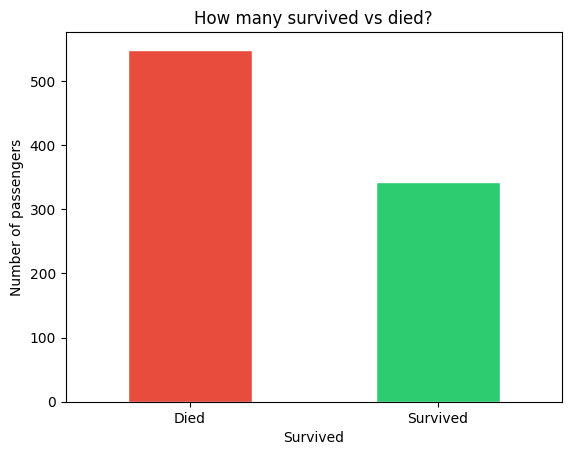

In [8]:
import matplotlib.pyplot as plt

train['Survived'].value_counts().plot(kind='bar', color=['#e74c3c','#2ecc71'],
                                      edgecolor='white')
plt.title('How many survived vs died?')
plt.xticks([0, 1], ['Died', 'Survived'], rotation=0)
plt.ylabel('Number of passengers')
plt.show()

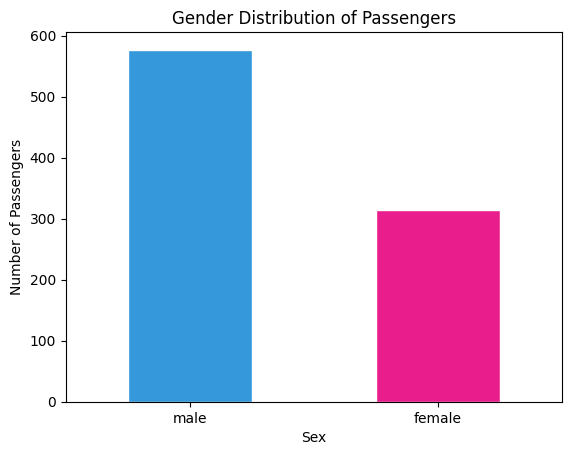

Sex
male      577
female    314
Name: count, dtype: int64

Percentage:
Sex
male      64.758698
female    35.241302
Name: proportion, dtype: float64


In [10]:
import matplotlib.pyplot as plt

train['Sex'].value_counts().plot(kind='bar',
                                  color=['#3498db', '#e91e8c'],
                                  edgecolor='white')
plt.title('Gender Distribution of Passengers')
plt.xticks(rotation=0)
plt.ylabel('Number of Passengers')
plt.show()

# Also print the exact numbers
print(train['Sex'].value_counts())
print("\nPercentage:")
print(train['Sex'].value_counts(normalize=True) * 100)

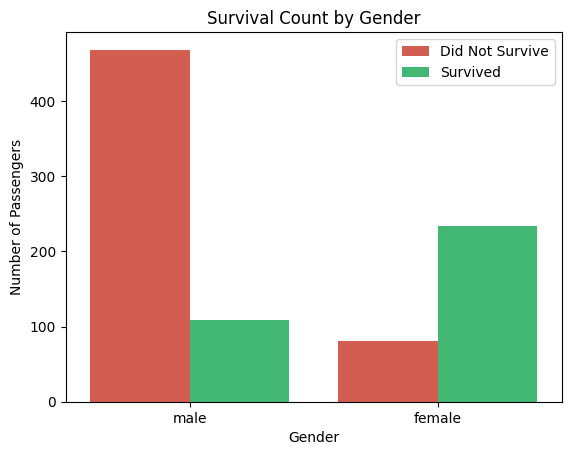

Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64

Survival rate by gender:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


In [11]:
import seaborn as sns

sns.countplot(data=train, x='Sex', hue='Survived',
              palette={0: '#e74c3c', 1: '#2ecc71'})

plt.title('Survival Count by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')
plt.legend(labels=['Did Not Survive', 'Survived'])
plt.show()

# Print the exact numbers
print(train.groupby('Sex')['Survived'].value_counts())
print("\nSurvival rate by gender:")
print(train.groupby('Sex')['Survived'].mean() * 100)

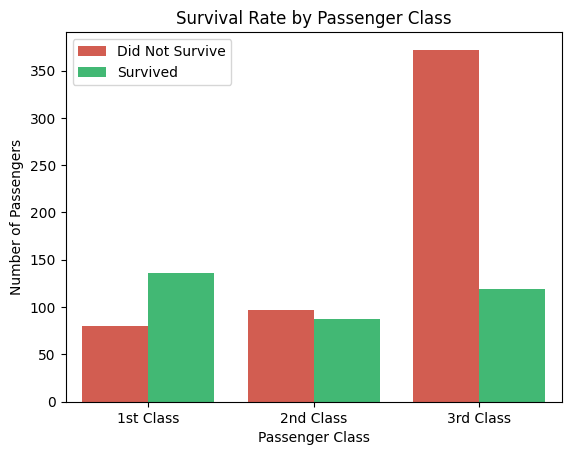

Pclass  Survived
1       1           136
        0            80
2       0            97
        1            87
3       0           372
        1           119
Name: count, dtype: int64

Survival rate by class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


In [12]:
sns.countplot(data=train, x='Pclass', hue='Survived',
              palette={0: '#e74c3c', 1: '#2ecc71'})

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')
plt.xticks([0, 1, 2], ['1st Class', '2nd Class', '3rd Class'])
plt.legend(labels=['Did Not Survive', 'Survived'])
plt.show()

# Print exact numbers
print(train.groupby('Pclass')['Survived'].value_counts())
print("\nSurvival rate by class:")
print(train.groupby('Pclass')['Survived'].mean() * 100)

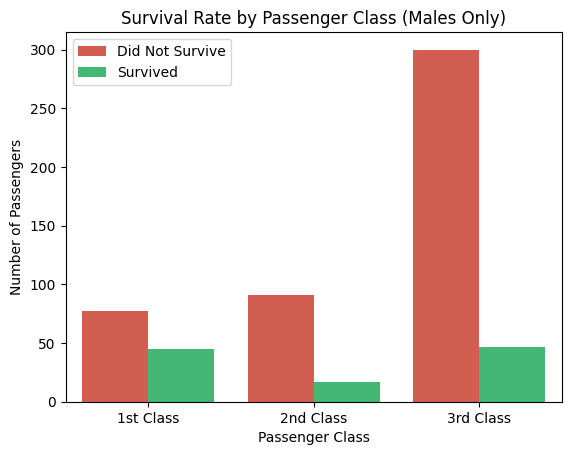

Pclass  Survived
1       0            77
        1            45
2       0            91
        1            17
3       0           300
        1            47
Name: count, dtype: int64

Male survival rate by class:
Pclass
1    36.885246
2    15.740741
3    13.544669
Name: Survived, dtype: float64


In [13]:
males = train[train['Sex'] == 'male']

sns.countplot(data=males, x='Pclass', hue='Survived',
              palette={0: '#e74c3c', 1: '#2ecc71'})

plt.title('Survival Rate by Passenger Class (Males Only)')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')
plt.xticks([0, 1, 2], ['1st Class', '2nd Class', '3rd Class'])
plt.legend(labels=['Did Not Survive', 'Survived'])
plt.show()

# Print exact numbers
print(males.groupby('Pclass')['Survived'].value_counts())
print("\nMale survival rate by class:")
print(males.groupby('Pclass')['Survived'].mean() * 100)

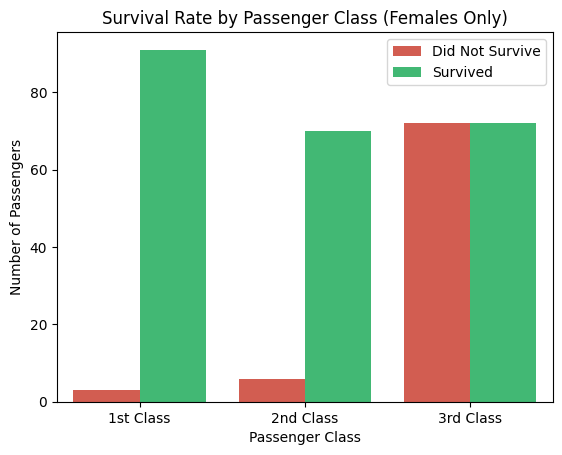

Pclass  Survived
1       1           91
        0            3
2       1           70
        0            6
3       0           72
        1           72
Name: count, dtype: int64

Female survival rate by class:
Pclass
1    96.808511
2    92.105263
3    50.000000
Name: Survived, dtype: float64


In [14]:
females = train[train['Sex'] == 'female']

sns.countplot(data=females, x='Pclass', hue='Survived',
              palette={0: '#e74c3c', 1: '#2ecc71'})

plt.title('Survival Rate by Passenger Class (Females Only)')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')
plt.xticks([0, 1, 2], ['1st Class', '2nd Class', '3rd Class'])
plt.legend(labels=['Did Not Survive', 'Survived'])
plt.show()

# Print exact numbers
print(females.groupby('Pclass')['Survived'].value_counts())
print("\nFemale survival rate by class:")
print(females.groupby('Pclass')['Survived'].mean() * 100)

In [15]:
# Load test data too since we clean both together
#test = pd.read_csv('test.csv')

print("Before dropping:")
print("Train columns:", list(train.columns))
print("Test columns:", list(test.columns))

Before dropping:
Train columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Test columns: ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [16]:
train = train.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
test = test.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

print("Train columns after dropping:", list(train.columns))
print("Test columns after dropping:", list(test.columns))

Train columns after dropping: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
Test columns after dropping: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


In [17]:
# Convert Sex
train['Sex'] = train['Sex'].map({'male': 0, 'female': 1})
test['Sex'] = test['Sex'].map({'male': 0, 'female': 1})

# Convert Embarked
train['Embarked'] = train['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
test['Embarked'] = test['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

# Confirm
print("Train sample:")
print(train.head())
print("\nAny remaining text columns?")
print(train.dtypes)

Train sample:
   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked
0         0       3    0  22.0      1      0   7.2500       0.0
1         1       1    1  38.0      1      0  71.2833       1.0
2         1       3    1  26.0      0      0   7.9250       0.0
3         1       1    1  35.0      1      0  53.1000       0.0
4         0       3    0  35.0      0      0   8.0500       0.0

Any remaining text columns?
Survived      int64
Pclass        int64
Sex           int64
Age         float64
SibSp         int64
Parch         int64
Fare        float64
Embarked    float64
dtype: object


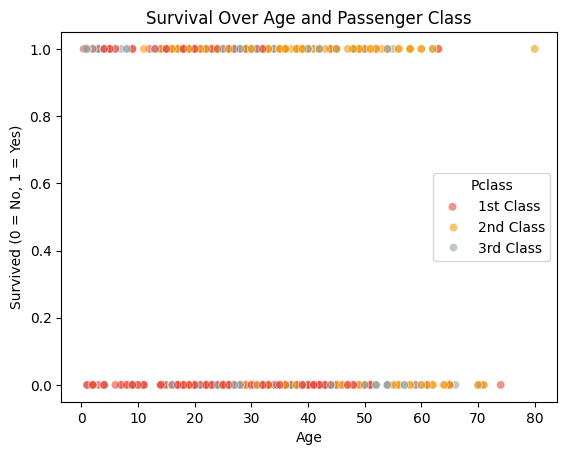

In [18]:
sns.scatterplot(data=train, x='Age', y='Survived',
                hue='Pclass', palette={1: '#f39c12', 2: '#95a5a6', 3: '#e74c3c'},
                alpha=0.6)

plt.title('Survival Over Age and Passenger Class')
plt.xlabel('Age')
plt.ylabel('Survived (0 = No, 1 = Yes)')
plt.legend(title='Pclass', labels=['1st Class', '2nd Class', '3rd Class'])
plt.show()

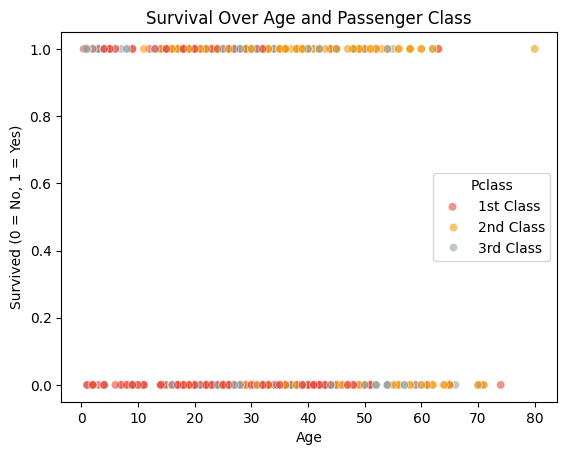

In [19]:
sns.scatterplot(data=train, x='Age', y='Survived',
                hue='Pclass', palette={1: '#f39c12', 2: '#95a5a6', 3: '#e74c3c'},
                alpha=0.6)

plt.title('Survival Over Age and Passenger Class')
plt.xlabel('Age')
plt.ylabel('Survived (0 = No, 1 = Yes)')
plt.legend(title='Pclass', labels=['1st Class', '2nd Class', '3rd Class'])
plt.show()

In [20]:
# Check how many are missing
print("Missing ages:", train['Age'].isnull().sum())

# Fill with median age
median_age = train['Age'].median()
print("Median age:", median_age)

train['Age'] = train['Age'].fillna(median_age)
test['Age'] = test['Age'].fillna(median_age)

# Confirm no more missing
print("Missing ages after fix:", train['Age'].isnull().sum())

Missing ages: 177
Median age: 28.0
Missing ages after fix: 0


In [21]:
# Create age groups for train
train['AgeGroup'] = pd.cut(train['Age'],
                            bins=[0, 12, 18, 35, 60, 100],
                            labels=['Child', 'Teenager', 'YoungAdult', 'Adult', 'Senior'])

# Create age groups for test
test['AgeGroup'] = pd.cut(test['Age'],
                           bins=[0, 12, 18, 35, 60, 100],
                           labels=['Child', 'Teenager', 'YoungAdult', 'Adult', 'Senior'])

# Check the distribution
print("Age group distribution:")
print(train['AgeGroup'].value_counts())

Age group distribution:
AgeGroup
YoungAdult    535
Adult         195
Teenager       70
Child          69
Senior         22
Name: count, dtype: int64


Survival rate by age group:
AgeGroup
Child         57.971014
Teenager      42.857143
YoungAdult    35.327103
Adult         40.000000
Senior        22.727273
Name: Survived, dtype: float64


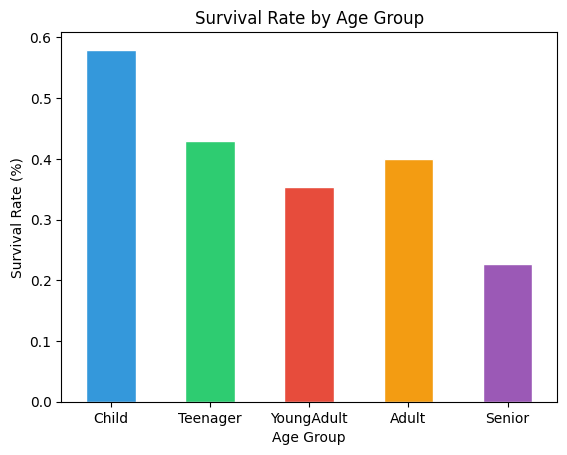

In [22]:
# Survival rate by age group
print("Survival rate by age group:")
print(train.groupby('AgeGroup', observed=True)['Survived'].mean() * 100)

# Plot it
train.groupby('AgeGroup', observed=True)['Survived'].mean().plot(
    kind='bar',
    color=['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6'],
    edgecolor='white'
)

plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [23]:
# Convert AgeGroup to numbers
train['AgeGroup'] = train['AgeGroup'].map({
    'Child': 0, 'Teenager': 1, 'YoungAdult': 2, 'Adult': 3, 'Senior': 4
})

test['AgeGroup'] = test['AgeGroup'].map({
    'Child': 0, 'Teenager': 1, 'YoungAdult': 2, 'Adult': 3, 'Senior': 4
})

print(train.head())

   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked AgeGroup
0         0       3    0  22.0      1      0   7.2500       0.0        2
1         1       1    1  38.0      1      0  71.2833       1.0        3
2         1       3    1  26.0      0      0   7.9250       0.0        2
3         1       1    1  35.0      1      0  53.1000       0.0        2
4         0       3    0  35.0      0      0   8.0500       0.0        2


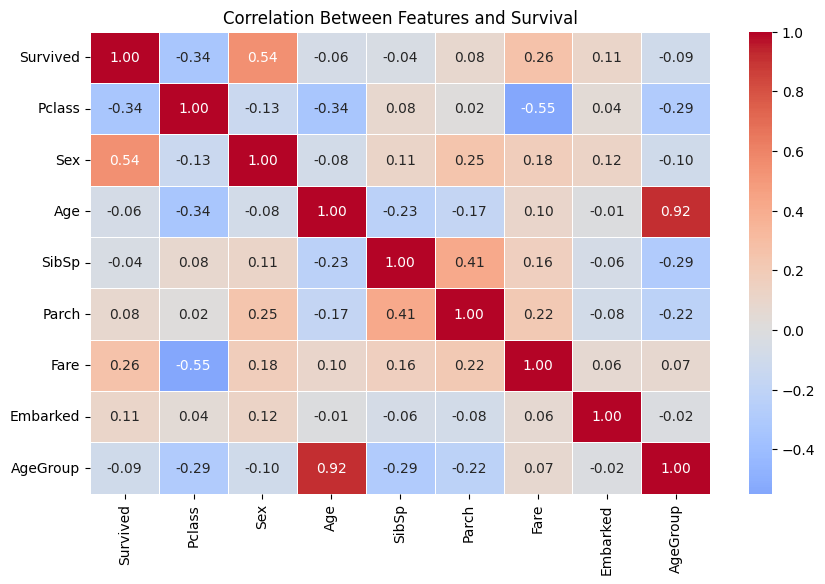

Correlation with Survived:
Survived    1.000000
Sex         0.543351
Fare        0.257307
Embarked    0.108669
Parch       0.081629
SibSp      -0.035322
Age        -0.064910
AgeGroup   -0.093191
Pclass     -0.338481
Name: Survived, dtype: float64


In [24]:
import seaborn as sns

# Calculate correlation
correlation = train.corr()

# Plot heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            center=0,
            linewidths=0.5)

plt.title('Correlation Between Features and Survival')
plt.show()

# Print just the correlation with Survived specifically
print("Correlation with Survived:")
print(correlation['Survived'].sort_values(ascending=False))

In [25]:
# Drop Age since AgeGroup captures the same info
train = train.drop(columns=['Age'])
test = test.drop(columns=['Age'])

# Fix missing Embarked (2 missing) with most common value
train['Embarked'] = train['Embarked'].fillna(train['Embarked'].mode()[0])
test['Embarked'] = test['Embarked'].fillna(test['Embarked'].mode()[0])

# Fix missing Fare in test (1 missing)
test['Fare'] = test['Fare'].fillna(test['Fare'].median())

# Confirm no missing values remain
print("Train missing values:")
print(train.isnull().sum())
print("\nTest missing values:")
print(test.isnull().sum())

Train missing values:
Survived    0
Pclass      0
Sex         0
SibSp       0
Parch       0
Fare        0
Embarked    0
AgeGroup    0
dtype: int64

Test missing values:
Pclass      0
Sex         0
SibSp       0
Parch       0
Fare        0
Embarked    0
AgeGroup    0
dtype: int64


### Third phase:
### Building the model and testing the accuracy (this process is where you start building models and choose a model based on accuracy metrics)
- Choose a model suitable for classification
- Fit the data
- Find out how "well" the model performs using some metrics
- Use cross validation to get the avg accuracy on the model you chose
- **Bonus 1**
    - Try other classification algorithms
    - Compare the accuracy metrics (including cross-validation) for the classification algorithms used by presenting them in a readable, easy to compare format
    - Choose a model with the best cross validation accuracy metric
- **Bonus 2**: Get the feature importance of your features using random forests
    (if you are not sure what that is or how to do it, google it!)

In [26]:
# X = everything except Survived
# y = Survived column only
X = train.drop(columns=['Survived'])
y = train['Survived']

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures we are using:")
print(list(X.columns))

X shape: (891, 7)
y shape: (891,)

Features we are using:
['Pclass', 'Sex', 'SibSp', 'Parch', 'Fare', 'Embarked', 'AgeGroup']


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# Create the model
model = LogisticRegression(max_iter=500)

# Fit the model on training data
model.fit(X, y)

# Check accuracy on training data
train_accuracy = model.score(X, y)
print(f"Training Accuracy: {train_accuracy * 100:.2f}%")

# Use cross validation to get a more reliable accuracy
cv_scores = cross_val_score(model, X, y, cv=5)
print(f"\nCross Validation Scores: {cv_scores}")
print(f"Average CV Accuracy: {cv_scores.mean() * 100:.2f}%")
print(f"Standard Deviation: {cv_scores.std() * 100:.2f}%")

Training Accuracy: 80.13%

Cross Validation Scores: [0.7877095  0.78651685 0.79213483 0.78089888 0.8258427 ]
Average CV Accuracy: 79.46%
Standard Deviation: 1.60%


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import pandas as pd

# Define all models
models = {
    'Logistic Regression':    LogisticRegression(max_iter=500),
    'Decision Tree':          DecisionTreeClassifier(random_state=42),
    'Random Forest':          RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting':      GradientBoostingClassifier(n_estimators=100, random_state=42),
    'K-Nearest Neighbors':    KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(kernel='rbf', random_state=42),
}

# Train and evaluate each model
results = []
for name, m in models.items():
    m.fit(X, y)
    train_acc = m.score(X, y)
    cv_scores = cross_val_score(m, X, y, cv=5)
    results.append({
        'Model': name,
        'Training Accuracy': f"{train_acc * 100:.2f}%",
        'CV Average': f"{cv_scores.mean() * 100:.2f}%",
        'CV Std Dev': f"{cv_scores.std() * 100:.2f}%"
    })

# Display as a neat table
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

                 Model Training Accuracy CV Average CV Std Dev
   Logistic Regression            80.13%     79.46%      1.60%
         Decision Tree            93.94%     79.91%      2.89%
         Random Forest            93.94%     81.04%      2.65%
     Gradient Boosting            88.66%     82.04%      2.91%
   K-Nearest Neighbors            84.40%     75.43%      2.80%
Support Vector Machine            67.79%     66.90%      4.56%


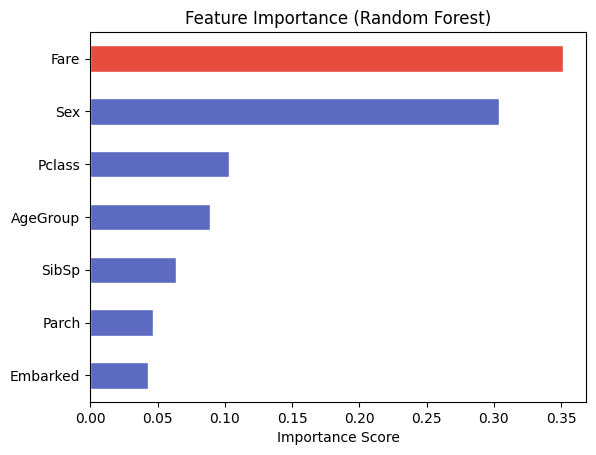


Feature Importance Ranking:
  Fare         0.3511  ███████████████████████████████████
  Sex          0.3037  ██████████████████████████████
  Pclass       0.1032  ██████████
  AgeGroup     0.0889  ████████
  SibSp        0.0638  ██████
  Parch        0.0467  ████
  Embarked     0.0426  ████


In [29]:
import numpy as np

# Get feature importances from Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X, y)

# Plot feature importances
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=True)

importances.plot(kind='barh',
                 color=['#e74c3c' if v == importances.max()
                        else '#5c6bc0' for v in importances.values],
                 edgecolor='white')

plt.title('Feature Importance (Random Forest)')
plt.xlabel('Importance Score')
plt.show()

print("\nFeature Importance Ranking:")
for feat, imp in importances.sort_values(ascending=False).items():
    bar = '█' * int(imp * 100)
    print(f"  {feat:<12} {imp:.4f}  {bar}")